In [20]:
import copy
import torch
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
from dataset import get_federated_dataloaders
from models import FraudMLP
from utils import calculate_entropy, compute_dynamic_mu
from client import train_client_dp, train_client_nodp
from server import federated_averaging, evaluate_model

In [21]:
def set_seed(seed=123):
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

set_seed(123)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


In [22]:
# ==============================================================================
# CELL 1: SETUP & FEDSHIELD MATHEMATICS
# ==============================================================================
num_clients = 5
client_loaders, test_loader = get_federated_dataloaders(filepath="data/creditcard.csv", num_clients=num_clients, alpha=0.1)

print("\n--- Exact Class Distribution per Bank ---")
entropies = []
for i, loader in enumerate(client_loaders):
    all_labels = []
    for _, labels in loader:
        all_labels.extend(labels.tolist())
    
    normal_count = all_labels.count(0)
    fraud_count = all_labels.count(1)
    total_cases = normal_count + fraud_count
    fraud_percent = (fraud_count / total_cases) * 100 if total_cases > 0 else 0
    
    print(f"Bank {i+1} | Normal: {normal_count} | Fraud: {fraud_count} ({fraud_percent:.4f}%)")
    
    # Calculate entropy for this bank
    entropies.append(calculate_entropy(np.array(all_labels), num_classes=2))

# Calculate Dynamic Parameters
dynamic_mus = compute_dynamic_mu(entropies, num_classes=2, mu_base=0.01, lambda_scale=0.5)
fedshield_weights = [np.exp(e) for e in entropies]

print("\n--- FedShield Dynamic Variables ---")
for i in range(num_clients):
    print(f"Bank {i+1} | Entropy: {entropies[i]:.4f} | mu_k: {dynamic_mus[i]:.4f} | Exp Weight: {fedshield_weights[i]:.4f}")

Loading and preparing federated partitions...

--- Exact Class Distribution per Bank ---
Bank 1 | Normal: 20029 | Fraud: 364 (1.7849%)
Bank 2 | Normal: 45 | Fraud: 0 (0.0000%)
Bank 3 | Normal: 41 | Fraud: 28 (40.5797%)
Bank 4 | Normal: 1086 | Fraud: 0 (0.0000%)
Bank 5 | Normal: 206250 | Fraud: 2 (0.0010%)

--- FedShield Dynamic Variables ---
Bank 1 | Entropy: 0.1292 | mu_k: 0.0144 | Exp Weight: 1.1379
Bank 2 | Entropy: -0.0000 | mu_k: 0.0150 | Exp Weight: 1.0000
Bank 3 | Entropy: 0.9742 | mu_k: 0.0101 | Exp Weight: 2.6492
Bank 4 | Entropy: -0.0000 | mu_k: 0.0150 | Exp Weight: 1.0000
Bank 5 | Entropy: 0.0002 | mu_k: 0.0150 | Exp Weight: 1.0002


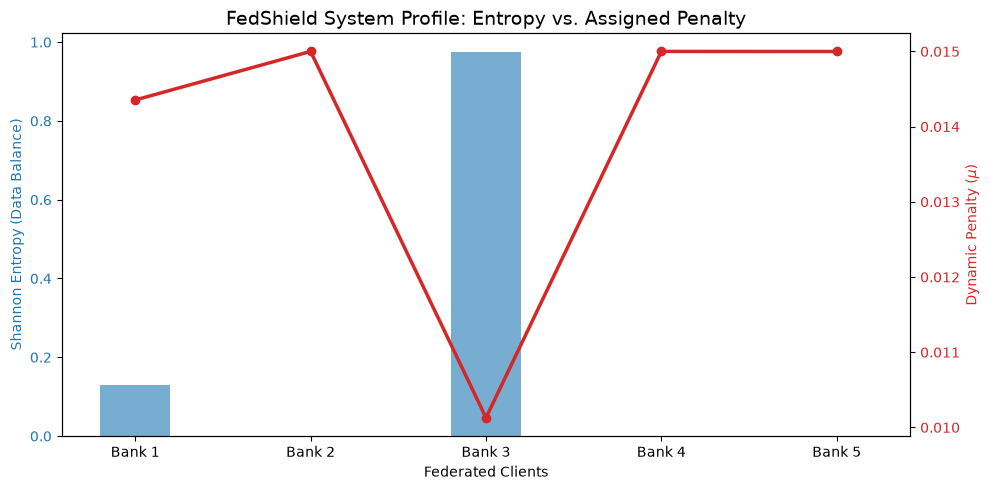

In [23]:
# VISUALIZATION 1: Entropy vs Dynamic Mu (System Profiling)
fig, ax1 = plt.subplots(figsize=(10, 5))

banks = [f"Bank {i+1}" for i in range(num_clients)]
color1 = 'tab:blue'
ax1.set_xlabel('Federated Clients')
ax1.set_ylabel('Shannon Entropy (Data Balance)', color=color1)
bars = ax1.bar(banks, entropies, color=color1, alpha=0.6, width=0.4, label="Entropy")
ax1.tick_params(axis='y', labelcolor=color1)

ax2 = ax1.twinx()  
color2 = 'tab:red'
ax2.set_ylabel('Dynamic Penalty ($\mu$)', color=color2)
lines = ax2.plot(banks, dynamic_mus, color=color2, marker='o', linewidth=2.5, label="Assigned $\mu$")
ax2.tick_params(axis='y', labelcolor=color2)

plt.title("FedShield System Profile: Entropy vs. Assigned Penalty", fontsize=14)
fig.tight_layout()
plt.show()

In [ ]:
# ==============================================================================
# CELL 2: DP EXPERIMENT (PHASE 2)
# ==============================================================================
'''
def run_dp_experiment(strategy="FedShield", num_rounds=15):
    print(f"\n--- Starting {strategy} (DP Enabled) ---")
    global_model = FraudMLP(freeze_backbone=False).to(device)
    roc_auc_history = []
    
    final_acc, final_prec, final_rec = 0, 0, 0
    
    for round_num in range(num_rounds):
        print(f"\n[Round {round_num + 1}/{num_rounds}]")
        client_models = []
        
        for i in range(num_clients):
            current_mu = 0.0 if strategy == "FedAvg" else (0.01 if strategy == "FedProx" else dynamic_mus[i])
            local_model = copy.deepcopy(global_model)
            
            trained_model, loss, eps = train_client_dp(
                local_model, global_model, client_loaders[i], current_mu, device, epochs=1
            )
            client_models.append(trained_model)
            print(f"  -> Bank {i+1} | Loss: {loss:.4f} | Eps: {eps:.2f}")
            
        if strategy == "FedShield":
            global_model = federated_averaging(global_model, client_models, weights=fedshield_weights)
        else:
            global_model = federated_averaging(global_model, client_models, weights=None)
            
        # Unpack all 5 metrics
        pr_auc, roc_auc, acc, prec, rec = evaluate_model(global_model, test_loader, device)
        roc_auc_history.append(roc_auc)
        print(f"Round {round_num+1} | ROC-AUC: {roc_auc:.4f}")
        
        # Store final round metrics
        if round_num == num_rounds - 1:
            final_acc, final_prec, final_rec = acc, prec, rec
            
    print(f"\n✅ FINAL {strategy} DP RESULTS -> ROC-AUC: {roc_auc_history[-1]:.4f} | PR-AUC: {pr_auc:.4f} | Fraud Prec: {final_prec:.4f} | Fraud Rec: {final_rec:.4f}")
    return roc_auc_history
'''
def run_dp_experiment(strategy="FedShield", num_rounds=15):
    print(f"\n========== STARTING DP PHASE: {strategy} ==========")
    global_model = FraudMLP(freeze_backbone=False).to(device)
    roc_auc_history = []
    
    final_acc, final_prec, final_rec = 0, 0, 0
    final_labels, final_preds = [], []
    
    for round_num in range(num_rounds):
        client_models = []
        is_final_round = (round_num == num_rounds - 1)
        
        for i in range(num_clients):
            current_mu = 0.0 if strategy == "FedAvg" else (0.01 if strategy == "FedProx" else dynamic_mus[i])
            local_model = copy.deepcopy(global_model)
            
            trained_model, loss, eps = train_client_dp(
                local_model, global_model, client_loaders[i], current_mu, device, epochs=1
            )
            client_models.append(trained_model)
            
        if strategy == "FedShield":
            global_model = federated_averaging(global_model, client_models, weights=fedshield_weights)
        else:
            global_model = federated_averaging(global_model, client_models, weights=None)
            
        # Grab the raw predictions only on the final round
        if is_final_round:
            pr_auc, roc_auc, acc, prec, rec, all_labels, all_preds = evaluate_model(global_model, test_loader, device, return_preds=True)
            final_labels, final_preds = all_labels, all_preds
        else:
            pr_auc, roc_auc, acc, prec, rec = evaluate_model(global_model, test_loader, device, return_preds=False)
            
        roc_auc_history.append(roc_auc)
        print(f"Round {round_num+1:02d}/{num_rounds:02d} | ROC-AUC: {roc_auc:.4f} | PR-AUC: {pr_auc:.4f}")
        
        if is_final_round:
            final_acc, final_prec, final_rec = acc, prec, rec

    print(f"\n✅ FINAL {strategy} DP RESULTS -> ROC-AUC: {roc_auc_history[-1]:.4f} | PR-AUC: {pr_auc:.4f} | Acc: {final_acc:.4f} | Fraud Prec: {final_prec:.4f} | Fraud Rec: {final_rec:.4f}")
    
    # Print the full report and plot the matrix
    print(f"\n--- {strategy} (DP) Classification Report ---")
    print(classification_report(final_labels, final_preds, target_names=["Normal", "Fraud"], digits=4))
    
    cm = confusion_matrix(final_labels, final_preds)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Normal", "Fraud"])
    disp.plot(cmap=plt.cm.Blues, values_format='d')
    plt.title(f"{strategy} DP Confusion Matrix")
    plt.show()
    
    return roc_auc_history


========== STARTING DP PHASE: FedAvg ==========


d:\BTech\Major Project\FedShield\venv\Lib\site-packages\opacus\privacy_engine.py:98: UserWarning: Secure RNG turned off. This is perfectly fine for experimentation as it allows for much faster training performance, but remember to turn it on and retrain one last time before production with ``secure_mode`` turned on.
  warnings.warn(
d:\BTech\Major Project\FedShield\venv\Lib\site-packages\opacus\accountants\analysis\prv\prvs.py:67: RuntimeWarning: divide by zero encountered in log
  z = np.log(np.where(t > np.log(1 - q), (np.exp(t) + q - 1) / q, 1))
d:\BTech\Major Project\FedShield\venv\Lib\site-packages\opacus\accountants\analysis\prv\prvs.py:70: RuntimeWarning: divide by zero encountered in log
  t > np.log(1 - q),


Round 01/15 | ROC-AUC: 0.0556 | PR-AUC: 0.0009


d:\BTech\Major Project\FedShield\venv\Lib\site-packages\opacus\privacy_engine.py:98: UserWarning: Secure RNG turned off. This is perfectly fine for experimentation as it allows for much faster training performance, but remember to turn it on and retrain one last time before production with ``secure_mode`` turned on.
  warnings.warn(
d:\BTech\Major Project\FedShield\venv\Lib\site-packages\opacus\accountants\analysis\prv\prvs.py:67: RuntimeWarning: divide by zero encountered in log
  z = np.log(np.where(t > np.log(1 - q), (np.exp(t) + q - 1) / q, 1))
d:\BTech\Major Project\FedShield\venv\Lib\site-packages\opacus\accountants\analysis\prv\prvs.py:70: RuntimeWarning: divide by zero encountered in log
  t > np.log(1 - q),


Round 02/15 | ROC-AUC: 0.0538 | PR-AUC: 0.0009


d:\BTech\Major Project\FedShield\venv\Lib\site-packages\opacus\privacy_engine.py:98: UserWarning: Secure RNG turned off. This is perfectly fine for experimentation as it allows for much faster training performance, but remember to turn it on and retrain one last time before production with ``secure_mode`` turned on.
  warnings.warn(
d:\BTech\Major Project\FedShield\venv\Lib\site-packages\opacus\accountants\analysis\prv\prvs.py:67: RuntimeWarning: divide by zero encountered in log
  z = np.log(np.where(t > np.log(1 - q), (np.exp(t) + q - 1) / q, 1))
d:\BTech\Major Project\FedShield\venv\Lib\site-packages\opacus\accountants\analysis\prv\prvs.py:70: RuntimeWarning: divide by zero encountered in log
  t > np.log(1 - q),


... (22 outputs left out)

Round 14/15 | ROC-AUC: 0.0545 | PR-AUC: 0.0009


d:\BTech\Major Project\FedShield\venv\Lib\site-packages\opacus\privacy_engine.py:98: UserWarning: Secure RNG turned off. This is perfectly fine for experimentation as it allows for much faster training performance, but remember to turn it on and retrain one last time before production with ``secure_mode`` turned on.
  warnings.warn(
d:\BTech\Major Project\FedShield\venv\Lib\site-packages\opacus\accountants\analysis\prv\prvs.py:67: RuntimeWarning: divide by zero encountered in log
  z = np.log(np.where(t > np.log(1 - q), (np.exp(t) + q - 1) / q, 1))
d:\BTech\Major Project\FedShield\venv\Lib\site-packages\opacus\accountants\analysis\prv\prvs.py:70: RuntimeWarning: divide by zero encountered in log
  t > np.log(1 - q),


Round 15/15 | ROC-AUC: 0.0547 | PR-AUC: 0.0009

✅ FINAL FedAvg DP RESULTS -> ROC-AUC: 0.0547 | PR-AUC: 0.0009 | Acc: 0.9983 | Fraud Prec: 0.0000 | Fraud Rec: 0.0000

--- FedAvg (DP) Classification Report ---
              precision    recall  f1-score   support

      Normal     0.9983    1.0000    0.9991     56864
       Fraud     0.0000    0.0000    0.0000        98

    accuracy                         0.9983     56962
   macro avg     0.4991    0.5000    0.4996     56962
weighted avg     0.9966    0.9983    0.9974     56962



d:\BTech\Major Project\FedShield\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
d:\BTech\Major Project\FedShield\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
d:\BTech\Major Project\FedShield\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result

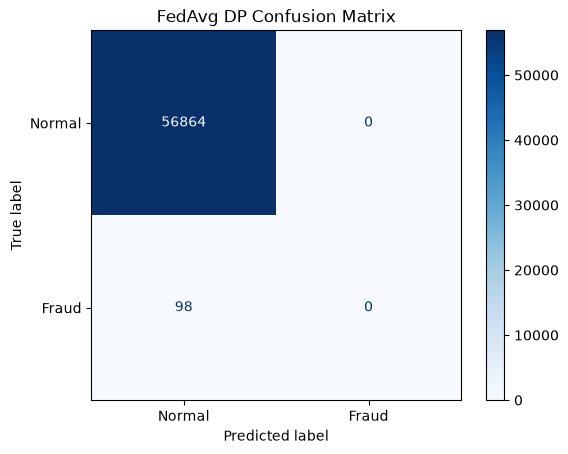

In [25]:
auc_fedavg_dp = run_dp_experiment("FedAvg", 15)

d:\BTech\Major Project\FedShield\venv\Lib\site-packages\opacus\privacy_engine.py:98: UserWarning: Secure RNG turned off. This is perfectly fine for experimentation as it allows for much faster training performance, but remember to turn it on and retrain one last time before production with ``secure_mode`` turned on.
  warnings.warn(



========== STARTING DP PHASE: FedProx ==========


d:\BTech\Major Project\FedShield\venv\Lib\site-packages\opacus\accountants\analysis\prv\prvs.py:67: RuntimeWarning: divide by zero encountered in log
  z = np.log(np.where(t > np.log(1 - q), (np.exp(t) + q - 1) / q, 1))
d:\BTech\Major Project\FedShield\venv\Lib\site-packages\opacus\accountants\analysis\prv\prvs.py:70: RuntimeWarning: divide by zero encountered in log
  t > np.log(1 - q),


Round 01/15 | ROC-AUC: 0.0617 | PR-AUC: 0.0009


d:\BTech\Major Project\FedShield\venv\Lib\site-packages\opacus\privacy_engine.py:98: UserWarning: Secure RNG turned off. This is perfectly fine for experimentation as it allows for much faster training performance, but remember to turn it on and retrain one last time before production with ``secure_mode`` turned on.
  warnings.warn(
d:\BTech\Major Project\FedShield\venv\Lib\site-packages\opacus\accountants\analysis\prv\prvs.py:67: RuntimeWarning: divide by zero encountered in log
  z = np.log(np.where(t > np.log(1 - q), (np.exp(t) + q - 1) / q, 1))
d:\BTech\Major Project\FedShield\venv\Lib\site-packages\opacus\accountants\analysis\prv\prvs.py:70: RuntimeWarning: divide by zero encountered in log
  t > np.log(1 - q),


Round 02/15 | ROC-AUC: 0.0597 | PR-AUC: 0.0009


... (23 outputs left out)

Round 14/15 | ROC-AUC: 0.0630 | PR-AUC: 0.0009


d:\BTech\Major Project\FedShield\venv\Lib\site-packages\opacus\privacy_engine.py:98: UserWarning: Secure RNG turned off. This is perfectly fine for experimentation as it allows for much faster training performance, but remember to turn it on and retrain one last time before production with ``secure_mode`` turned on.
  warnings.warn(
d:\BTech\Major Project\FedShield\venv\Lib\site-packages\opacus\accountants\analysis\prv\prvs.py:67: RuntimeWarning: divide by zero encountered in log
  z = np.log(np.where(t > np.log(1 - q), (np.exp(t) + q - 1) / q, 1))
d:\BTech\Major Project\FedShield\venv\Lib\site-packages\opacus\accountants\analysis\prv\prvs.py:70: RuntimeWarning: divide by zero encountered in log
  t > np.log(1 - q),


Round 15/15 | ROC-AUC: 0.0632 | PR-AUC: 0.0009

✅ FINAL FedProx DP RESULTS -> ROC-AUC: 0.0632 | PR-AUC: 0.0009 | Acc: 0.9983 | Fraud Prec: 0.0000 | Fraud Rec: 0.0000

--- FedProx (DP) Classification Report ---
              precision    recall  f1-score   support

      Normal     0.9983    1.0000    0.9991     56864
       Fraud     0.0000    0.0000    0.0000        98

    accuracy                         0.9983     56962
   macro avg     0.4991    0.5000    0.4996     56962
weighted avg     0.9966    0.9983    0.9974     56962



d:\BTech\Major Project\FedShield\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
d:\BTech\Major Project\FedShield\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
d:\BTech\Major Project\FedShield\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result

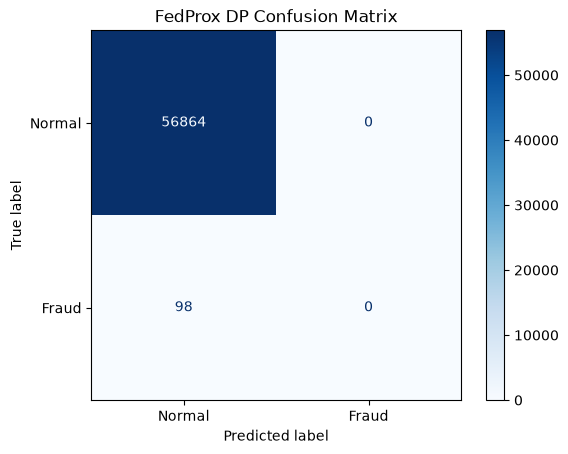

In [26]:
auc_fedprox_dp = run_dp_experiment("FedProx", 15)


========== STARTING DP PHASE: FedShield ==========


d:\BTech\Major Project\FedShield\venv\Lib\site-packages\opacus\privacy_engine.py:98: UserWarning: Secure RNG turned off. This is perfectly fine for experimentation as it allows for much faster training performance, but remember to turn it on and retrain one last time before production with ``secure_mode`` turned on.
  warnings.warn(
d:\BTech\Major Project\FedShield\venv\Lib\site-packages\opacus\accountants\analysis\prv\prvs.py:67: RuntimeWarning: divide by zero encountered in log
  z = np.log(np.where(t > np.log(1 - q), (np.exp(t) + q - 1) / q, 1))
d:\BTech\Major Project\FedShield\venv\Lib\site-packages\opacus\accountants\analysis\prv\prvs.py:70: RuntimeWarning: divide by zero encountered in log
  t > np.log(1 - q),


Round 01/15 | ROC-AUC: 0.0873 | PR-AUC: 0.0009


d:\BTech\Major Project\FedShield\venv\Lib\site-packages\opacus\privacy_engine.py:98: UserWarning: Secure RNG turned off. This is perfectly fine for experimentation as it allows for much faster training performance, but remember to turn it on and retrain one last time before production with ``secure_mode`` turned on.
  warnings.warn(
d:\BTech\Major Project\FedShield\venv\Lib\site-packages\opacus\accountants\analysis\prv\prvs.py:67: RuntimeWarning: divide by zero encountered in log
  z = np.log(np.where(t > np.log(1 - q), (np.exp(t) + q - 1) / q, 1))
d:\BTech\Major Project\FedShield\venv\Lib\site-packages\opacus\accountants\analysis\prv\prvs.py:70: RuntimeWarning: divide by zero encountered in log
  t > np.log(1 - q),


Round 02/15 | ROC-AUC: 0.0804 | PR-AUC: 0.0009


d:\BTech\Major Project\FedShield\venv\Lib\site-packages\opacus\privacy_engine.py:98: UserWarning: Secure RNG turned off. This is perfectly fine for experimentation as it allows for much faster training performance, but remember to turn it on and retrain one last time before production with ``secure_mode`` turned on.
  warnings.warn(
d:\BTech\Major Project\FedShield\venv\Lib\site-packages\opacus\accountants\analysis\prv\prvs.py:67: RuntimeWarning: divide by zero encountered in log
  z = np.log(np.where(t > np.log(1 - q), (np.exp(t) + q - 1) / q, 1))
d:\BTech\Major Project\FedShield\venv\Lib\site-packages\opacus\accountants\analysis\prv\prvs.py:70: RuntimeWarning: divide by zero encountered in log
  t > np.log(1 - q),


... (22 outputs left out)

Round 14/15 | ROC-AUC: 0.0741 | PR-AUC: 0.0009


d:\BTech\Major Project\FedShield\venv\Lib\site-packages\opacus\privacy_engine.py:98: UserWarning: Secure RNG turned off. This is perfectly fine for experimentation as it allows for much faster training performance, but remember to turn it on and retrain one last time before production with ``secure_mode`` turned on.
  warnings.warn(
d:\BTech\Major Project\FedShield\venv\Lib\site-packages\opacus\accountants\analysis\prv\prvs.py:67: RuntimeWarning: divide by zero encountered in log
  z = np.log(np.where(t > np.log(1 - q), (np.exp(t) + q - 1) / q, 1))
d:\BTech\Major Project\FedShield\venv\Lib\site-packages\opacus\accountants\analysis\prv\prvs.py:70: RuntimeWarning: divide by zero encountered in log
  t > np.log(1 - q),


Round 15/15 | ROC-AUC: 0.0744 | PR-AUC: 0.0009

✅ FINAL FedShield DP RESULTS -> ROC-AUC: 0.0744 | PR-AUC: 0.0009 | Acc: 0.9983 | Fraud Prec: 0.0000 | Fraud Rec: 0.0000

--- FedShield (DP) Classification Report ---
              precision    recall  f1-score   support

      Normal     0.9983    1.0000    0.9991     56864
       Fraud     0.0000    0.0000    0.0000        98

    accuracy                         0.9983     56962
   macro avg     0.4991    0.5000    0.4996     56962
weighted avg     0.9966    0.9983    0.9974     56962



d:\BTech\Major Project\FedShield\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
d:\BTech\Major Project\FedShield\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
d:\BTech\Major Project\FedShield\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result

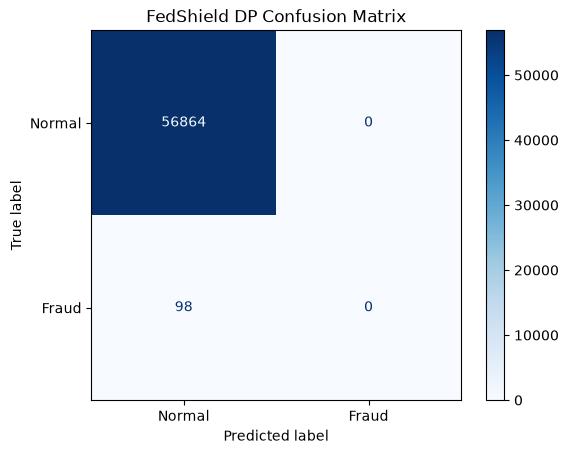

In [27]:
auc_fedshield_dp = run_dp_experiment("FedShield", 15)

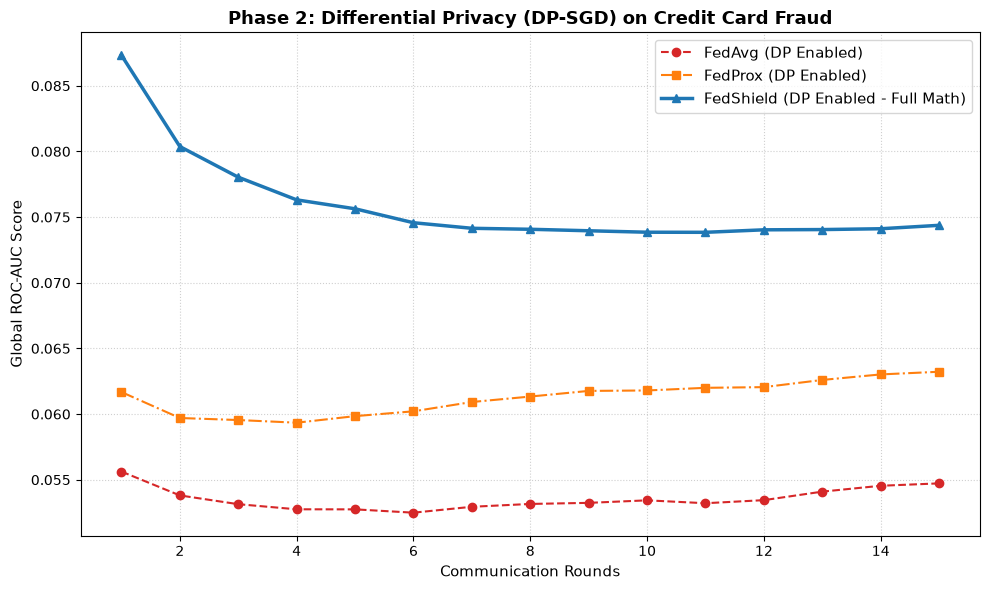

In [28]:
# ==============================================================================
# CELL 2.5: PLOT DP EXPERIMENT RESULTS
# ==============================================================================
plt.figure(figsize=(10, 6))
rounds = range(1, 16) 

plt.plot(rounds, auc_fedavg_dp, marker='o', linestyle='--', color='tab:red', label='FedAvg (DP Enabled)')
plt.plot(rounds, auc_fedprox_dp, marker='s', linestyle='-.', color='tab:orange', label='FedProx (DP Enabled)')
plt.plot(rounds, auc_fedshield_dp, marker='^', linestyle='-', color='tab:blue', linewidth=2.5, label='FedShield (DP Enabled - Full Math)')

plt.title("Phase 2: Differential Privacy (DP-SGD) on Credit Card Fraud", fontsize=13, fontweight='bold')
plt.xlabel("Communication Rounds", fontsize=11)
plt.ylabel("Global ROC-AUC Score", fontsize=11)
plt.legend(fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

In [29]:
# ==============================================================================
# CELL 3: NON-DP ABLATION STUDY (PHASE 3)
# ==============================================================================
'''
def run_nodp_experiment(strategy="FedShield", num_rounds=15):
    print(f"\n--- Starting {strategy} (NO DP - Ablation Study) ---")
    global_model = FraudMLP(freeze_backbone=False).to(device)
    roc_auc_history = []
    
    final_acc, final_prec, final_rec = 0, 0, 0
    
    for round_num in range(num_rounds):
        client_models = []
        for i in range(num_clients):
            current_mu = 0.0 if strategy == "FedAvg" else (0.01 if strategy == "FedProx" else dynamic_mus[i])
            local_model = copy.deepcopy(global_model)
            
            trained_model, _, _ = train_client_nodp(
                local_model, global_model, client_loaders[i], current_mu, device, epochs=1
            )
            client_models.append(trained_model)
            
        # FORCE weights=None FOR ALL TO ISOLATE CLIENT-SIDE PENALTY
        global_model = federated_averaging(global_model, client_models, weights=None)
        
        # Unpack all 5 metrics
        pr_auc, roc_auc, acc, prec, rec = evaluate_model(global_model, test_loader, device)
        roc_auc_history.append(roc_auc)
        print(f"Round {round_num+1} | ROC-AUC: {roc_auc:.4f}")
        
        # Store final round metrics
        if round_num == num_rounds - 1:
            final_acc, final_prec, final_rec = acc, prec, rec
            
    print(f"\n✅ FINAL {strategy} NO-DP RESULTS -> ROC-AUC: {roc_auc_history[-1]:.4f} | PR-AUC: {pr_auc:.4f} | Fraud Prec: {final_prec:.4f} | Fraud Rec: {final_rec:.4f}")
    return roc_auc_history
'''
def run_nodp_experiment(strategy="FedShield", num_rounds=15):
    print(f"\n========== STARTING NON-DP PHASE: {strategy} ==========")
    global_model = FraudMLP(freeze_backbone=False).to(device)
    roc_auc_history = []
    
    final_acc, final_prec, final_rec = 0, 0, 0
    final_labels, final_preds = [], []
    
    for round_num in range(num_rounds):
        client_models = []
        is_final_round = (round_num == num_rounds - 1)
        
        
        for i in range(num_clients):
            if strategy == "FedAvg":
                current_mu = 0.0
            elif strategy == "FedProx":
                current_mu = 0.01
            elif strategy in ["FedShield_Local", "FedShield_Full"]:
                current_mu = dynamic_mus[i]
                
            local_model = copy.deepcopy(global_model)
            
            trained_model, _, _ = train_client_nodp(
                local_model, global_model, client_loaders[i], current_mu, device, epochs=1
            )
            client_models.append(trained_model)
            
        
        # Only the Full FedShield uses the server-side exponential weights
        if strategy == "FedShield_Full":
            global_model = federated_averaging(global_model, client_models, weights=fedshield_weights)
        else:
            global_model = federated_averaging(global_model, client_models, weights=None)
        
        if is_final_round:
            pr_auc, roc_auc, acc, prec, rec, all_labels, all_preds = evaluate_model(global_model, test_loader, device, return_preds=True)
            final_labels, final_preds = all_labels, all_preds
        else:
            pr_auc, roc_auc, acc, prec, rec = evaluate_model(global_model, test_loader, device, return_preds=False)
            
        roc_auc_history.append(roc_auc)
        print(f"Round {round_num+1:02d}/{num_rounds:02d} | ROC-AUC: {roc_auc:.4f} | PR-AUC: {pr_auc:.4f}")
        
        if is_final_round:
            final_acc, final_prec, final_rec = acc, prec, rec
            
    print(f"\n✅ FINAL {strategy} NO-DP RESULTS -> ROC-AUC: {roc_auc_history[-1]:.4f} | PR-AUC: {pr_auc:.4f} | Acc: {final_acc:.4f} | Fraud Prec: {final_prec:.4f} | Fraud Rec: {final_rec:.4f}")
    
    print(f"\n--- {strategy} (No-DP) Classification Report ---")
    print(classification_report(final_labels, final_preds, target_names=["Normal", "Fraud"], digits=4))
    
    cm = confusion_matrix(final_labels, final_preds)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Normal", "Fraud"])
    disp.plot(cmap=plt.cm.Greens, values_format='d') 
    plt.title(f"{strategy} No-DP Confusion Matrix")
    plt.show()
    
    return roc_auc_history


========== STARTING NON-DP PHASE: FedAvg ==========
Round 01/15 | ROC-AUC: 0.1008 | PR-AUC: 0.0009
Round 02/15 | ROC-AUC: 0.1007 | PR-AUC: 0.0009
Round 03/15 | ROC-AUC: 0.1397 | PR-AUC: 0.0009
Round 04/15 | ROC-AUC: 0.2353 | PR-AUC: 0.0011
Round 05/15 | ROC-AUC: 0.3995 | PR-AUC: 0.0036
Round 06/15 | ROC-AUC: 0.6063 | PR-AUC: 0.1308
Round 07/15 | ROC-AUC: 0.7638 | PR-AUC: 0.4193
Round 08/15 | ROC-AUC: 0.8373 | PR-AUC: 0.5349
Round 09/15 | ROC-AUC: 0.8585 | PR-AUC: 0.5801
Round 10/15 | ROC-AUC: 0.8735 | PR-AUC: 0.6104
Round 11/15 | ROC-AUC: 0.8897 | PR-AUC: 0.6169
Round 12/15 | ROC-AUC: 0.9034 | PR-AUC: 0.6310
Round 13/15 | ROC-AUC: 0.9137 | PR-AUC: 0.6374
Round 14/15 | ROC-AUC: 0.9209 | PR-AUC: 0.6430
Round 15/15 | ROC-AUC: 0.9273 | PR-AUC: 0.6465

✅ FINAL FedAvg NO-DP RESULTS -> ROC-AUC: 0.9273 | PR-AUC: 0.6465 | Acc: 0.9988 | Fraud Prec: 0.7857 | Fraud Rec: 0.4490

--- FedAvg (No-DP) Classification Report ---
              precision    recall  f1-score   support

      Normal     0.9

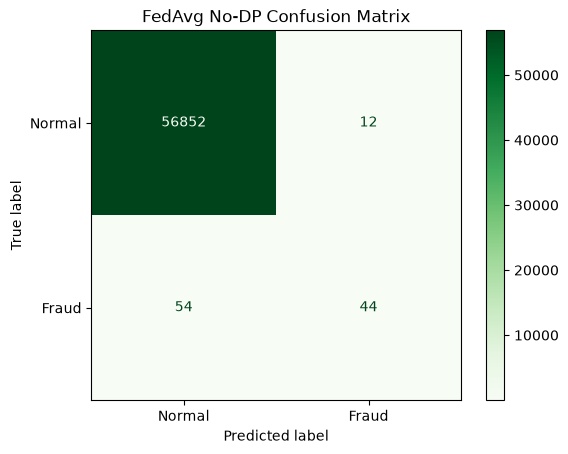

In [30]:
auc_fedavg_nodp = run_nodp_experiment("FedAvg", 15)


========== STARTING NON-DP PHASE: FedProx ==========
Round 01/15 | ROC-AUC: 0.2042 | PR-AUC: 0.0010
Round 02/15 | ROC-AUC: 0.2260 | PR-AUC: 0.0011
Round 03/15 | ROC-AUC: 0.3455 | PR-AUC: 0.0030
Round 04/15 | ROC-AUC: 0.4803 | PR-AUC: 0.0346
Round 05/15 | ROC-AUC: 0.6768 | PR-AUC: 0.1962
Round 06/15 | ROC-AUC: 0.7862 | PR-AUC: 0.4654
Round 07/15 | ROC-AUC: 0.8069 | PR-AUC: 0.5845
Round 08/15 | ROC-AUC: 0.8286 | PR-AUC: 0.6088
Round 09/15 | ROC-AUC: 0.8428 | PR-AUC: 0.6324
Round 10/15 | ROC-AUC: 0.8495 | PR-AUC: 0.6324
Round 11/15 | ROC-AUC: 0.8572 | PR-AUC: 0.6309
Round 12/15 | ROC-AUC: 0.8647 | PR-AUC: 0.6374
Round 13/15 | ROC-AUC: 0.8724 | PR-AUC: 0.6402
Round 14/15 | ROC-AUC: 0.8802 | PR-AUC: 0.6462
Round 15/15 | ROC-AUC: 0.8917 | PR-AUC: 0.6474

✅ FINAL FedProx NO-DP RESULTS -> ROC-AUC: 0.8917 | PR-AUC: 0.6474 | Acc: 0.9990 | Fraud Prec: 0.8030 | Fraud Rec: 0.5408

--- FedProx (No-DP) Classification Report ---
              precision    recall  f1-score   support

      Normal     

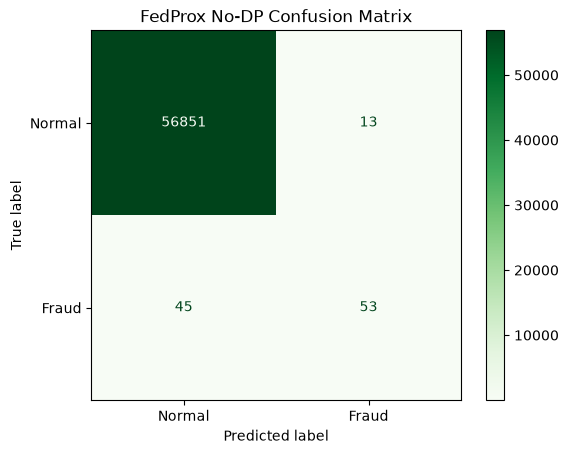

In [31]:
auc_fedprox_nodp = run_nodp_experiment("FedProx", 15)


========== STARTING NON-DP PHASE: FedShield_Local ==========


Round 01/15 | ROC-AUC: 0.1368 | PR-AUC: 0.0009
Round 02/15 | ROC-AUC: 0.1312 | PR-AUC: 0.0009
Round 03/15 | ROC-AUC: 0.1935 | PR-AUC: 0.0010
Round 04/15 | ROC-AUC: 0.3931 | PR-AUC: 0.0015
Round 05/15 | ROC-AUC: 0.7137 | PR-AUC: 0.1723
Round 06/15 | ROC-AUC: 0.8048 | PR-AUC: 0.4622
Round 07/15 | ROC-AUC: 0.8393 | PR-AUC: 0.5546
Round 08/15 | ROC-AUC: 0.8532 | PR-AUC: 0.5995
Round 09/15 | ROC-AUC: 0.8615 | PR-AUC: 0.6112
Round 10/15 | ROC-AUC: 0.8720 | PR-AUC: 0.6231
Round 11/15 | ROC-AUC: 0.8818 | PR-AUC: 0.6261
Round 12/15 | ROC-AUC: 0.8894 | PR-AUC: 0.6342
Round 13/15 | ROC-AUC: 0.8957 | PR-AUC: 0.6435
Round 14/15 | ROC-AUC: 0.9021 | PR-AUC: 0.6526
Round 15/15 | ROC-AUC: 0.9079 | PR-AUC: 0.6552

✅ FINAL FedShield_Local NO-DP RESULTS -> ROC-AUC: 0.9079 | PR-AUC: 0.6552 | Acc: 0.9990 | Fraud Prec: 0.7971 | Fraud Rec: 0.5612

--- FedShield_Local (No-DP) Classification Report ---
              precision    recall  f1-score   support

      Normal     0.9992    0.9998    0.9995     56864
 

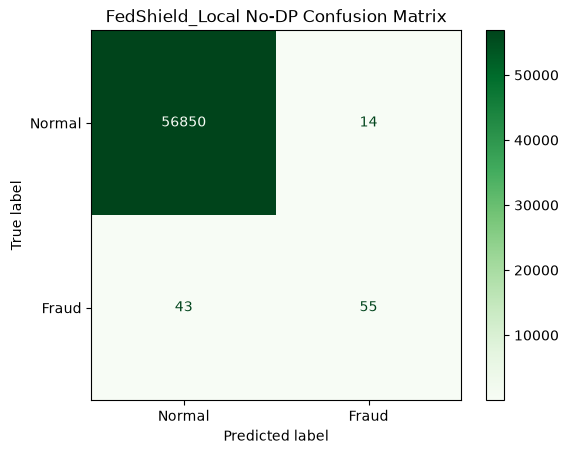

In [32]:
auc_fedshield_nodp = run_nodp_experiment("FedShield_Local", 15)


========== STARTING NON-DP PHASE: FedShield_Full ==========
Round 01/15 | ROC-AUC: 0.0881 | PR-AUC: 0.0009
Round 02/15 | ROC-AUC: 0.1109 | PR-AUC: 0.0009
Round 03/15 | ROC-AUC: 0.1680 | PR-AUC: 0.0010
Round 04/15 | ROC-AUC: 0.2890 | PR-AUC: 0.0011
Round 05/15 | ROC-AUC: 0.5270 | PR-AUC: 0.0049
Round 06/15 | ROC-AUC: 0.7097 | PR-AUC: 0.1422
Round 07/15 | ROC-AUC: 0.7977 | PR-AUC: 0.3569
Round 08/15 | ROC-AUC: 0.8287 | PR-AUC: 0.4821
Round 09/15 | ROC-AUC: 0.8490 | PR-AUC: 0.5434
Round 10/15 | ROC-AUC: 0.8646 | PR-AUC: 0.5859
Round 11/15 | ROC-AUC: 0.8751 | PR-AUC: 0.5984
Round 12/15 | ROC-AUC: 0.8938 | PR-AUC: 0.6197
Round 13/15 | ROC-AUC: 0.9055 | PR-AUC: 0.6352
Round 14/15 | ROC-AUC: 0.9133 | PR-AUC: 0.6611
Round 15/15 | ROC-AUC: 0.9180 | PR-AUC: 0.6653

✅ FINAL FedShield_Full NO-DP RESULTS -> ROC-AUC: 0.9180 | PR-AUC: 0.6653 | Acc: 0.9985 | Fraud Prec: 0.8824 | Fraud Rec: 0.1531

--- FedShield_Full (No-DP) Classification Report ---
              precision    recall  f1-score   suppo

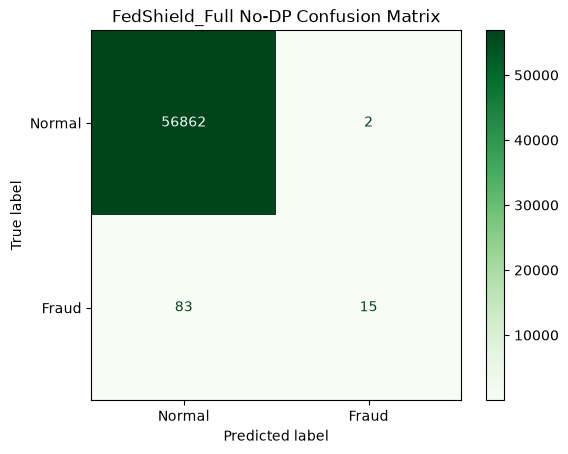

In [33]:
auc_fedshield_full = run_nodp_experiment("FedShield_Full", 15)

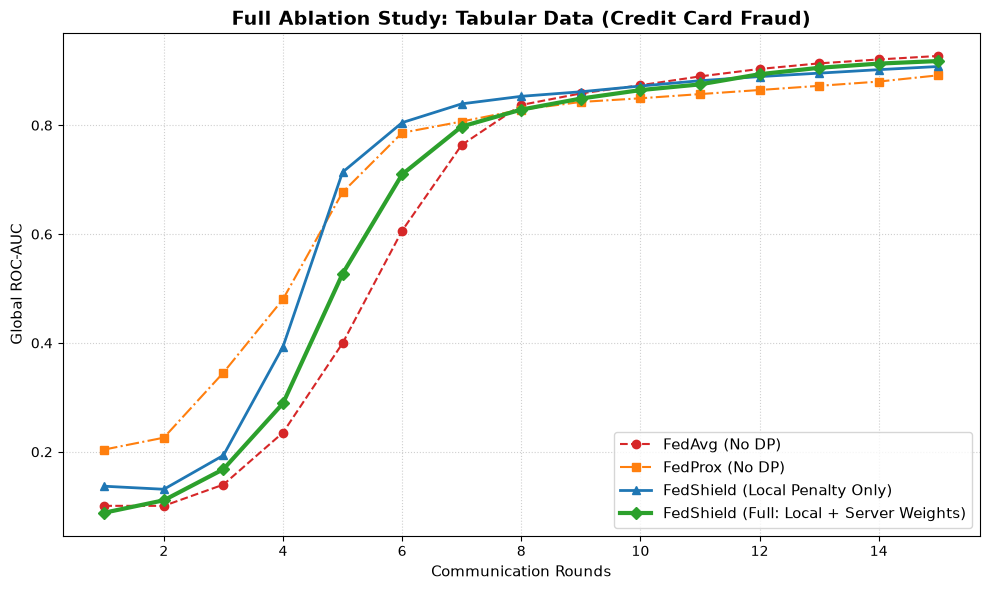

In [34]:
# ==============================================================================
# CELL 4: PLOT ABLATION RESULTS
# ==============================================================================
# Plot the 4-step Ablation Study
plt.figure(figsize=(10, 6))
rounds_range = range(1, 16)

plt.plot(rounds_range, auc_fedavg_nodp, marker='o', linestyle='--', color='tab:red', label='FedAvg (No DP)')
plt.plot(rounds_range, auc_fedprox_nodp, marker='s', linestyle='-.', color='tab:orange', label='FedProx (No DP)')
plt.plot(rounds_range, auc_fedshield_nodp, marker='^', linestyle='-', color='tab:blue', linewidth=2, label='FedShield (Local Penalty Only)')
plt.plot(rounds_range, auc_fedshield_full, marker='D', linestyle='-', color='tab:green', linewidth=3, label='FedShield (Full: Local + Server Weights)')

plt.title("Full Ablation Study: Tabular Data (Credit Card Fraud)", fontsize=14, fontweight='bold')
plt.xlabel("Communication Rounds", fontsize=11)
plt.ylabel("Global ROC-AUC", fontsize=11)
plt.legend(fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()